In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance

In [2]:
DATA_FILE = "gpc_dataset.csv"

FEATURE_COLUMNS = [
    "NaOH_Molarity",
    "Activator_Ratio",
    "A_B_Ratio",
    "Bacteria(%)",
    "Temperature_Degree_Celsius",
   
]
TARGET_COLUMN = "Compressive_Strength_MPa"

In [3]:
def load_data():
    if os.path.exists(DATA_FILE):
        df = pd.read_csv(DATA_FILE)
        print(f"Loaded real dataset from {DATA_FILE}: {df.shape[0]} rows")
    else:
        print(f" '{DATA_FILE}' not found")
        df = pd.DataFrame(rows)

    return df

In [4]:
def train_svr(X_train, y_train):
    pipeline= Pipeline([
        ("scaler", StandardScaler()),
        ("svr", SVR(kernel="rbf"))
    ])
    param_grid = {
    "svr__C": [1,10,50,100,200],
    "svr__epsilon": [0.01,0.1,0.5,1],
    "svr__gamma": ["scale", "auto", 0.01,0.1,1],
    }
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring="r2",
    n_jobs= -1,
    verbose=1,
    )
    grid.fit(X_train, y_train)
    print("\nBest parameters found:")
    print(grid.best_params_)
    print(f"Best CV R^2 score: {grid.best_score_:.4f}")
    return grid.best_estimator_

In [5]:
df = load_data()
df = df.dropna(subset=FEATURE_COLUMNS + [TARGET_COLUMN])
X = df[FEATURE_COLUMNS].values
y = df[TARGET_COLUMN].values
X_train,X_test, y_train, y_test = train_test_split(
    X,y, test_size=0.2, random_state=42
)
model = train_svr(X_train, y_train)

Loaded real dataset from gpc_dataset.csv: 70 rows
Fitting 5 folds for each of 100 candidates, totalling 500 fits

Best parameters found:
{'svr__C': 1, 'svr__epsilon': 1, 'svr__gamma': 0.01}
Best CV R^2 score: -0.0417


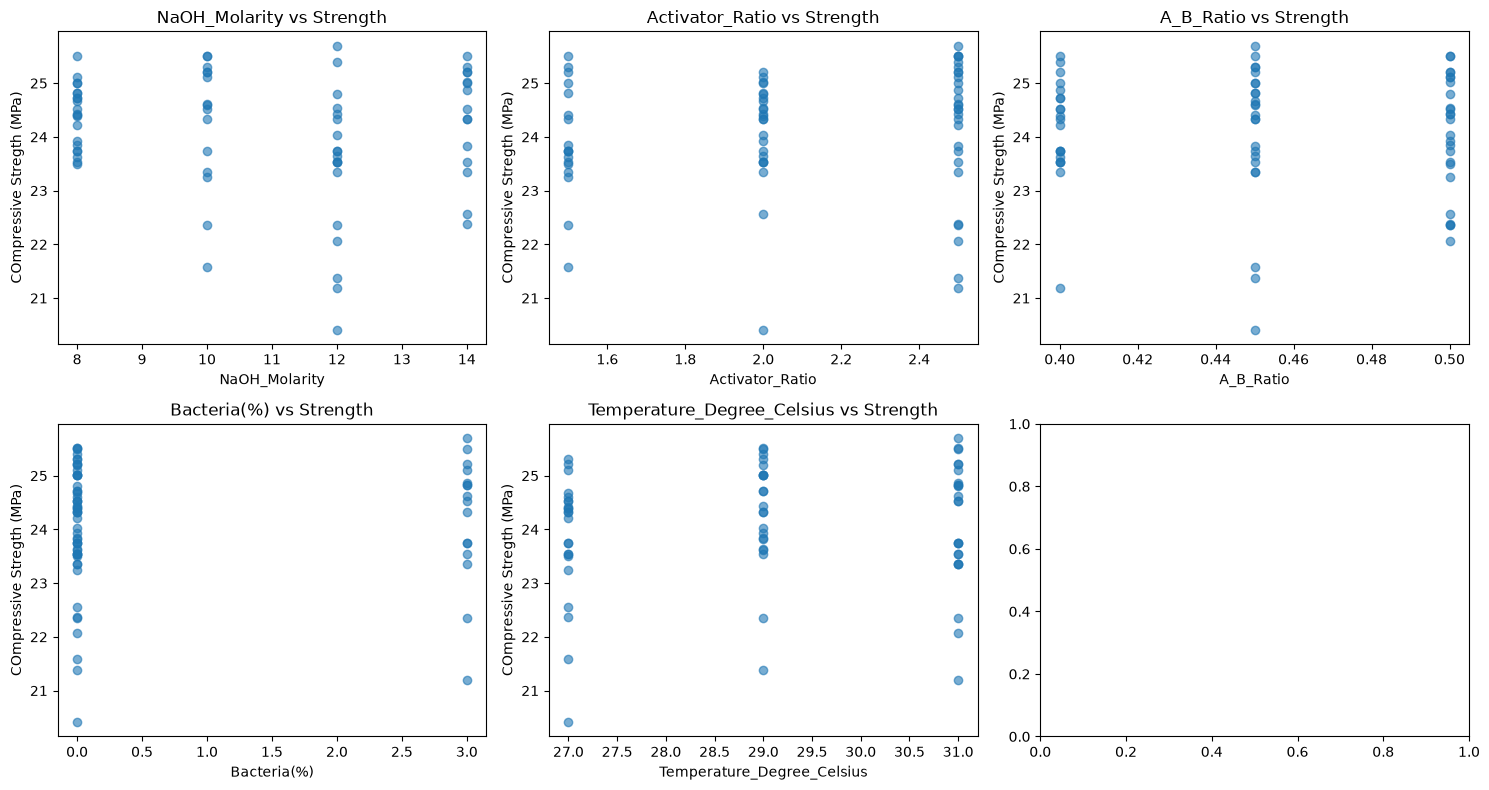

In [6]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2,3, figsize=(15,8))
axes =axes.flatten()
for i, col in enumerate(FEATURE_COLUMNS):
    axes[i].scatter(df[col], df[TARGET_COLUMN], alpha=0.6)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("COmpressive Stregth (MPa)")
    axes[i].set_title(f"{col} vs Strength")

plt.tight_layout()
plt.savefig("scatter_diagnostics.png", dpi=150)
plt.show()

In [7]:
outliers=df[df[TARGET_COLUMN]<22.5].sort_values(TARGET_COLUMN)
print(outliers)

    NaOH_Molarity  Activator_Ratio  A_B_Ratio  Bacteria(%)  \
39             12              2.0       0.45            0   
47             12              2.5       0.40            3   
49             12              2.5       0.45            0   
30             10              1.5       0.45            0   
53             12              2.5       0.50            0   
34             10              1.5       0.50            0   
54             12              2.5       0.50            3   
55             14              2.5       0.50            0   

    Temperature_Degree_Celsius  Compressive_Strength_MPa  
39                          27                     20.41  
47                          31                     21.19  
49                          29                     21.38  
30                          27                     21.58  
53                          31                     22.07  
34                          29                     22.36  
54                          

In [8]:
df_clean=df[df[TARGET_COLUMN]>=22.5]
print(df_clean[FEATURE_COLUMNS +[TARGET_COLUMN]].corr()[TARGET_COLUMN])

NaOH_Molarity                -0.025684
Activator_Ratio               0.311402
A_B_Ratio                     0.040055
Bacteria(%)                   0.113955
Temperature_Degree_Celsius    0.143998
Compressive_Strength_MPa      1.000000
Name: Compressive_Strength_MPa, dtype: float64


In [9]:
df = load_data()
df = df.dropna(subset=FEATURE_COLUMNS + [TARGET_COLUMN])
df_clean=df[df[TARGET_COLUMN] >=22.5]
X = df_clean[FEATURE_COLUMNS].values
y = df_clean[TARGET_COLUMN].values
X_train,X_test, y_train, y_test = train_test_split(
    X,y, test_size=0.2, random_state=42
)
model = train_svr(X_train, y_train)

Loaded real dataset from gpc_dataset.csv: 70 rows
Fitting 5 folds for each of 100 candidates, totalling 500 fits

Best parameters found:
{'svr__C': 10, 'svr__epsilon': 0.5, 'svr__gamma': 0.01}
Best CV R^2 score: 0.0148


In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error,r2_score
import numpy as np

y_pred= model.predict(X_test)

mae=mean_absolute_error(y_test,y_pred)
mse= mean_squared_error(y_test,y_pred)
rsme=np.sqrt(mse)
r2=r2_score(y_test,y_pred)
mape=np.mean(np.abs((y_test - y_pred)/ y_test))*100

print(f"R^2:{r2:.4f}")
print(f"MAE:{mae:.4f} MPa")
print(f"MSE:{mse:.4f} MPa")
print(f"RMSE:{np.sqrt(mse):.4f} MPa")
print(f"MAPE:{mape:.2f} %")

import pandas as pd
def get_metrics(y_true, y_pred, label):
    return{
        "Set": label,
        "R^2": r2_score(y_true,y_pred),
        "MAE": mean_absolute_error(y_true,y_pred),
        "MSE": mean_squared_error(y_true,y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true,y_pred)),
        "MAPE(%)": np.mean(np.abs((y_true - y_pred)/ y_true))*100
}
y_train_pred=model.predict(X_train)
y_test_pred=model.predict(X_test)

results=pd.DataFrame([
    get_metrics(y_train, y_train_pred, "Train"),
    get_metrics(y_test, y_test_pred, "Test"),
])
print(results)

R^2:-0.0428
MAE:0.6886 MPa
MSE:0.6612 MPa
RMSE:0.8132 MPa
MAPE:2.81 %
     Set       R^2       MAE       MSE      RMSE   MAPE(%)
0  Train  0.201656  0.531213  0.389771  0.624317  2.173800
1   Test -0.042831  0.688603  0.661233  0.813162  2.805133


Saved plot as predicted_vs_actual.png


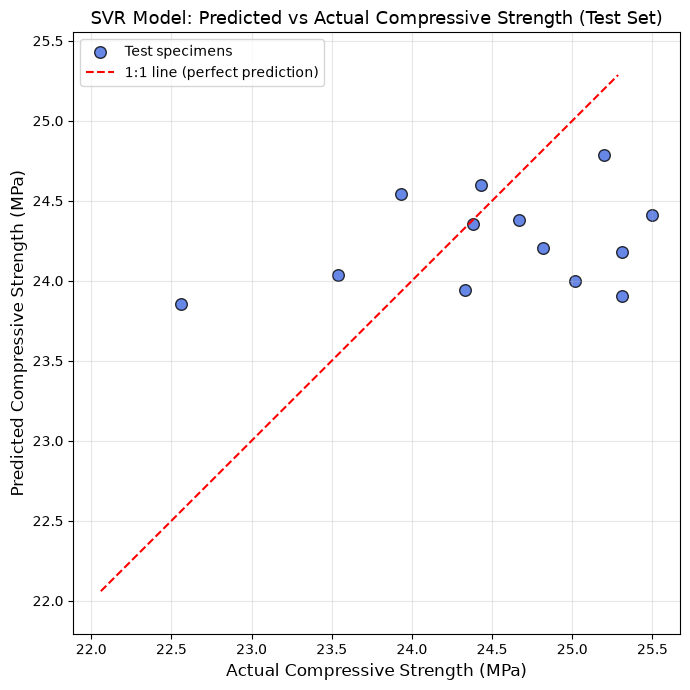

In [11]:
import matplotlib.pyplot as plt
import numpy as np

y_test_pred=model.predict(X_test)
plt.figure(figsize=(7,7))
plt.scatter(y_test,y_test_pred, color="royalblue", edgecolor="k", s=70, alpha=0.8, label="Test specimens")
min_val=min(y_test.min(), y_test_pred.min()) - 0.5
max_val=min(y_test.max(), y_test_pred.max()) + 0.5
plt.plot([min_val, max_val], [min_val, max_val], "r--", linewidth=1.5, label="1:1 line (perfect prediction)")

plt.xlabel("Actual Compressive Strength (MPa)", fontsize=12)
plt.ylabel("Predicted Compressive Strength (MPa)", fontsize=12)
plt.title("SVR Model: Predicted vs Actual Compressive Strength (Test Set)", fontsize=13)
plt.legend()
plt.grid(alpha=0.3)
plt.axis("equal")
plt.tight_layout()

plt.savefig("predicted_vs_actual.png", dpi=200)
print("Saved plot as predicted_vs_actual.png")
plt.show()

In [12]:
import numpy as np
import pandas as pd
import itertools

naoh_molarity_range=np.arange(8, 14.01,0.5)
activator_ratio_range=np.arange(1.5,2.51,0.1)
a_b_ratio_range=np.arange(0.4,0.51,0.1)
bacteria_range=np.arange(0,3.01,0.5)
temperature_range=np.arange(27,31.01,1.0)

FEATURE_COLUMNS = [
    "NaOH_Molarity",
    "Activator_Ratio",
    "A_B_Ratio",
    "Bacteria(%)",
    "Temperature_Degree_Celsius",
   
]
combinations=list(itertools.product(
    naoh_molarity_range,
    activator_ratio_range,
    a_b_ratio_range,
    bacteria_range,
    temperature_range,
))
grid_df=pd.DataFrame(combinations, columns=FEATURE_COLUMNS)
print(f"Total combinations to evaluate:{len(grid_df)}")
X_grid=grid_df[FEATURE_COLUMNS].values
predicted_strength=model.predict(X_grid)
grid_df["Predicted_Strength_MPa"]=predicted_strength

top_10=grid_df.sort_values("Predicted_Strength_MPa", ascending=False).head(10)
print("\n--- Top 10 Model-Predicted Mixes(Exploratory Only)---")
print(top_10.to_string(index=False))

best_mix=top_10.iloc[0]
print("\n--- Single Best Predicted Mix---")
for col in FEATURE_COLUMNS:
    print(f"{col}: {best_mix[col]}")
print(f"Predicted Compressive Strength:{best_mix['Predicted_Strength_MPa']:.2f} MPa")

top_10.to_csv("top_10_predicted_mixes.csv", index=False)
print("\nSaved top_10_predicted_mixes.csv")

Total combinations to evaluate:10010

--- Top 10 Model-Predicted Mixes(Exploratory Only)---
 NaOH_Molarity  Activator_Ratio  A_B_Ratio  Bacteria(%)  Temperature_Degree_Celsius  Predicted_Strength_MPa
           8.0              2.5        0.5          3.0                        31.0               25.155058
           8.0              2.5        0.5          2.5                        31.0               25.152022
           8.0              2.5        0.5          2.0                        31.0               25.145598
           8.0              2.5        0.5          1.5                        31.0               25.135846
           8.5              2.5        0.5          3.0                        31.0               25.123176
           8.0              2.5        0.5          1.0                        31.0               25.122858
           8.5              2.5        0.5          2.5                        31.0               25.118511
           8.5              2.5        0.5  

--- Permutation Feature Importance (mean R2 drop) ---
Activator_Ratio               0.348798
Temperature_Degree_Celsius    0.079434
NaOH_Molarity                 0.047118
A_B_Ratio                     0.010134
Bacteria(%)                  -0.014521
dtype: float64


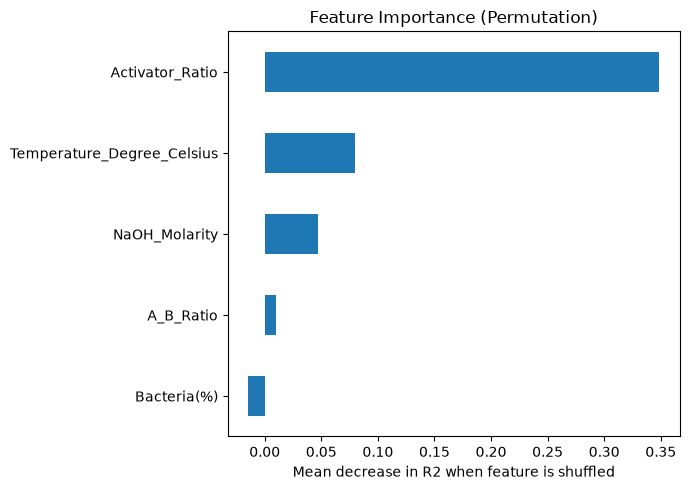

Saved feature_importance.png


In [13]:
result = permutation_importance(
    model, X_test, y_test,
    n_repeats=30, random_state=42, scoring="r2"
)
importances = pd.Series(result.importances_mean, index=FEATURE_COLUMNS)
importances = importances.sort_values(ascending=True)

print("--- Permutation Feature Importance (mean R2 drop) ---")
print(importances.sort_values(ascending=False))

plt.figure(figsize=(7,5))
importances.plot(kind="barh")
plt.xlabel("Mean decrease in R2 when feature is shuffled")
plt.title("Feature Importance (Permutation)")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=200)
plt.show()
print("Saved feature_importance.png")

In [14]:
scaler = model.named_steps["scaler"]

scaler_df = pd.DataFrame({
    "Feature": FEATURE_COLUMNS, 
    "Mean (mu)": scaler.mean_,
    "Std_Dev (sigma)": scaler.scale_,
})

scaler_df.to_csv("scaler_parameters.csv",index=False)
print(scaler_df)
print("Saved scaler_parameters.csv")

                      Feature  Mean (mu)  Std_Dev (sigma)
0               NaOH_Molarity  10.612245         2.220648
1             Activator_Ratio   2.061224         0.399396
2                   A_B_Ratio   0.446939         0.040918
3                 Bacteria(%)   0.673469         1.251738
4  Temperature_Degree_Celsius  29.244898         1.647888
Saved scaler_parameters.csv


In [15]:
svr=model.named_steps["svr"]
support_vectors=svr.support_vectors_
dual_coefs=svr.dual_coef_[0]

n_sv = len(support_vectors)
sv_df=pd.DataFrame(support_vectors, columns=[f"{f}_scaled" for f in FEATURE_COLUMNS])
sv_df.insert(0, "Support_Vector_Index", range(1, n_sv + 1))
sv_df["Dual_Coefficient (alpha_i - alpha_i*)"] = dual_coefs

sv_df.to_csv("support_vectors.csv", index=False)
print(f"Saved {n_sv} support vectors + dual coefficients to support_vectors.csv")
print(sv_df.head())

intercept = svr.intercept_[0]
print(f"Intercept (b): {intercept:.6f}")

Saved 26 support vectors + dual coefficients to support_vectors.csv
   Support_Vector_Index  NaOH_Molarity_scaled  Activator_Ratio_scaled  \
0                     1             -1.176343               -0.153293   
1                     2             -0.275705               -1.405184   
2                     3              1.525570                1.098599   
3                     4             -1.176343               -1.405184   
4                     5             -1.176343               -1.405184   

   A_B_Ratio_scaled  Bacteria(%)_scaled  Temperature_Degree_Celsius_scaled  \
0          0.074813           -0.538028                          -0.148613   
1          1.296762           -0.538028                           1.065061   
2         -1.147136           -0.538028                          -0.148613   
3          1.296762            1.858641                           1.065061   
4          1.296762           -0.538028                          -1.362288   

   Dual_Coefficient (alp